# ⚠️ PRACTICE COPY: runs on the FAKE match

This is a copy of `03_first_submission.ipynb` that scores against the **fake** answers in
`evaluation/gt/FAKE_possession_gt.csv` instead of the real public 5 minutes.

It only works after you have made the fake data:

```
python practice/make_fake_data.py
```

The fake answer key covers the **whole match**, not just 5 minutes, so the scores here mean more than on the real public window. 
Everything else is the organisers' notebook, unchanged. Where the text below quotes real numbers (17 possessions, 41% missing ball...), those are about the real match. Your fake numbers will be a bit different.


# 🎯 From tracking data to a scored submission

This notebook takes you the whole way: load the tracking, build a possession label for every
frame, write the submission file, and score it. By the end you will have beaten the trivial
baselines, and you will have seen on your own screen why the challenge is ranked on `spellF1`
and not on per-frame accuracy.

It needs **numpy, pandas and matplotlib** — no kloppy, no video decoder. The algorithm is
deliberately the simplest thing that is not a constant guess, so everything you add from here
is an improvement you can measure.

---

## 1. Where the data is

Nothing in this repository hard-codes a filename. `games.asset_paths()` builds every path from
one place, so if you keep the bundle somewhere else you set `MTAH_DATA_DIR` and change nothing
else.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import games

for name, path in sorted(games.asset_paths(source='tactical').items()):
    print('%-14s %-46s %s' % (name, os.path.basename(path),
                              'ok' if os.path.isfile(path) else 'MISSING'))

atd_meta       BAR-ATH_tactical_atd.xml                       ok
atd_raw        BAR-ATH_tactical_atd.txt                       ok
homography     BAR-ATH_tactical_homography.csv                MISSING
smart_tagging  BAR-ATH_tactical_smart_tagging.xml             ok
video          BAR-ATH_tactical.mp4                           MISSING


The videos are large and this notebook does not need them. The two ATD files are what matter.

## 2. Read the tracking, and meet the problem

`starter/baseline.py` reads the raw ATD with the standard library and numpy — one pass over
199,319 lines, a minute or two.

For every frame it finds the **tracked player nearest the ball** and returns that team. Where
the tracking cannot see the ball, it returns nothing.

In [2]:
import baseline

codes = baseline.build()   # 0 = home, 1 = away, -1 = no answer

teams: H = FAKE Barcelona, A = FAKE Athletic Club
reading BAR-ATH_tactical_atd.txt ...
  ball located on 88717 of 199319 frames (44.5%)



In [ ]:
#determine the frame and how long the 
#camera was filing for
codes
print(codes[:20])
print(codes[11185:11200])
199319/25
7972.76/60


[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


132.87933333333334

In [32]:
countBar = 0
countAlt = 0
countIdk = 0
start = 11185

firstHalf = codes[11185:90652]
for i in range(len(firstHalf)):
    if (firstHalf[i] == 0):
            countBar += 1
    elif (firstHalf[i] == 1):
            countAlt += 1
    elif (firstHalf[i] == -1):
           countIdk += 1

print(countBar, countAlt, countIdk)


for i in range(len(firstHalf)):
       if(firstHalf[i] == -1):
              print (start + i)
              break
       








21936 21898 35633
11245


### The ball is missing far more often than you would guess

This is the most important single fact about the dataset, and the reason a ball-only approach
is harder than it sounds. Look at where the gaps are before you design around them.

ball located on 88717 of 199319 frames (44.5%)


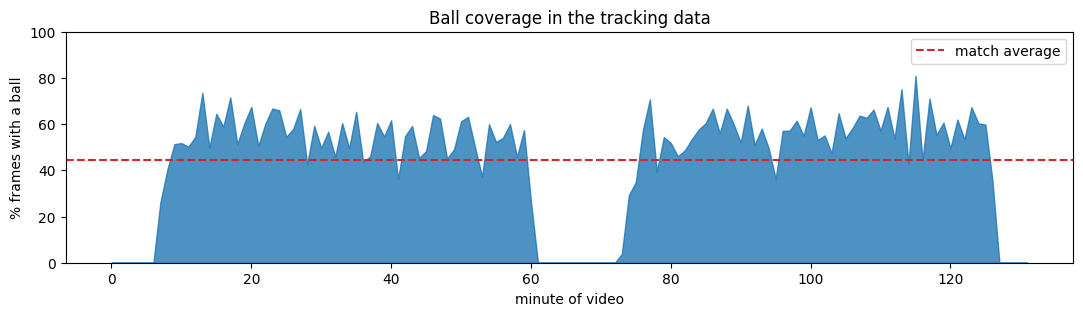

In [3]:
seen = codes != baseline.NOBODY
print('ball located on %d of %d frames (%.1f%%)' % (seen.sum(), len(seen), 100 * seen.mean()))

# Coverage per minute, so the halftime hole and the in-play gaps are both visible.
per_minute = seen[:len(seen) // 1500 * 1500].reshape(-1, 1500).mean(axis=1)

fig, ax = plt.subplots(figsize=(13, 3))
ax.fill_between(np.arange(len(per_minute)), per_minute * 100, color='#1f77b4', alpha=.8)
ax.axhline(100 * seen.mean(), color='#d62728', ls='--', label='match average')
ax.set_xlabel('minute of video'); ax.set_ylabel('% frames with a ball')
ax.set_ylim(0, 100); ax.legend(); ax.set_title('Ball coverage in the tracking data')
plt.show()

The trough in the middle is halftime, where there is no ground truth either. The dips during
play are the ones that cost you: occlusions, crowded boxes, and the ball in the air.

## 3. Your first submission

A submission is a CSV with one row per video frame and a label in `H` / `A` / `D` / `X`. That
is the entire format. Write the raw nearest-player answer and check it.

In [4]:
labels_raw = baseline.smooth(codes, 0)   # no smoothing yet
path = baseline.write_submission('../evaluation/results_fake/my_first.csv', labels_raw)

print(pd.Series(labels_raw).value_counts().to_string())
print()
print(open(path).read(40))

D    110602
A     45142
H     43575

frame,label
0,D
1,D
2,D
3,D
4,D
5,D
6,D



In [5]:
!python ../evaluation/validate_submission.py ../evaluation/results_fake/my_first.csv

OK    my_first.csv
      199319 rows, frame 0..199318

      label counts
        H    43575   21.9%
        A    45142   22.6%
        D   110602   55.5%
        X        0    0.0%

      reports 13542 possessions of mean 0.3 s

Valid. Note this checks the format only -- it says nothing about whether the labels are right.
Score it against the public ground truth with run_evaluation.py.


**Always run the validator on the exact file you are about to submit.** It applies the same
checks the official scorer applies, and a file that fails them scores nothing.

Read the last line as well as the first. The format is fine — but look at how many possessions
it claims.

## 4. Score it

Against the public five minutes of ground truth that ship with the repository.

In [6]:
sys.path.insert(0, os.path.abspath('../evaluation'))
import json
import possession_metrics as pm

gt = pm.label_codes(pm.read_label_csv('../evaluation/gt/FAKE_possession_gt.csv'))

def score(labels):
    """The two headline numbers, plus how many possessions the labels imply."""
    r = pm.evaluate(gt, pm.label_codes(labels))
    return {'macroF1': round(r['macro_f1'], 4), 'spellF1': round(r['spell_f1_mean'], 4),
            'possessions': r['n_pred_spells'],
            'mean_dur_s': round(r['mean_spell_duration_s'], 1)}

meta = json.load(open('../evaluation/gt/FAKE_possession_gt_meta.json'))
print('ground truth: %d possessions of mean %.1f s' % (meta['n_possessions'], meta['mean_possession_duration_s']))
print(score(labels_raw))

ground truth: 369 possessions of mean 13.9 s
{'macroF1': 0.4676, 'spellF1': 0.0029, 'possessions': 13542, 'mean_dur_s': 0.3}


`macroF1` looks almost respectable. `spellF1` is close to zero.

The reason is in the possession count. The raw labels flicker between teams frame by frame, so
instead of a few dozen possessions they report hundreds of tiny ones. Per-frame scoring barely
notices. `spellF1` — which counts each possession once, the way a coach does — notices at once.

## 5. Smooth it, and watch the two metrics disagree

One change: a majority vote over a window centred on each frame. Nothing else about the
algorithm changes.

In [7]:
rows = []
for window in (0, 12, 25, 50, 75, 125, 200):
    rows.append(dict(window=window, **score(baseline.smooth(codes, window))))

table = pd.DataFrame(rows).set_index('window')
table

,macroF1,spellF1,possessions,mean_dur_s
window,,,,
0,0.4676,0.0029,13542,0.3
12,0.5322,0.0513,3230,1.5
25,0.5617,0.1274,2121,2.6
50,0.5536,0.2613,1229,5.0
75,0.5390,0.3501,810,7.7
125,0.5239,0.3757,554,11.4
200,0.5066,0.3117,419,15.1


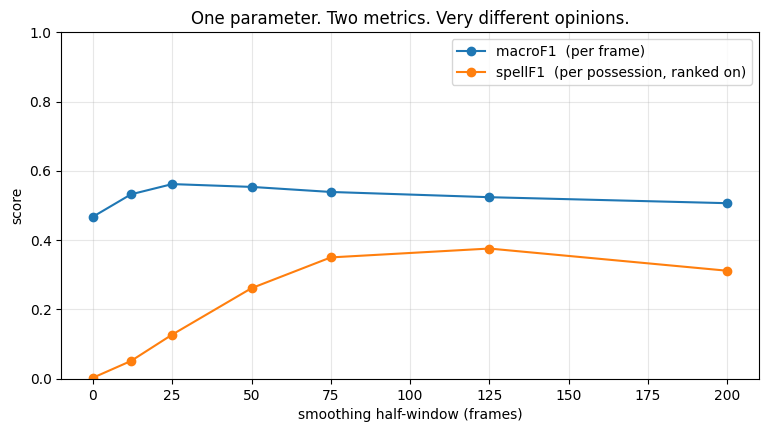

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(table.index, table['macroF1'], 'o-', label='macroF1  (per frame)')
ax.plot(table.index, table['spellF1'], 'o-', label='spellF1  (per possession, ranked on)')
ax.set_xlabel('smoothing half-window (frames)'); ax.set_ylabel('score')
ax.set_ylim(0, 1); ax.legend(); ax.grid(alpha=.3)
ax.set_title('One parameter. Two metrics. Very different opinions.')
plt.show()

`macroF1` is nearly flat across the whole sweep. `spellF1` climbs by a factor of five, then
falls again.

That gap is the argument of [EVALUATION.md](../EVALUATION.md): no per-frame metric can
represent possession, because the overwhelming majority of frames sit in the middle of one where
nothing is happening. Optimise for the wrong one and you will tune yourself into a worse
submission.

## 6. A warning that costs nothing to learn here

The window that wins above is **not** the window that wins on the full match.

Scored on the whole match, `±50` beats `±125` — the reverse of what these five minutes say.
Seventeen possessions cannot rank anything: one missed possession moves `spellF1` by roughly six
points.

Use the public window to check that your pipeline is **correct**, never to choose between two
versions of it. When a gap looks real, run `--bootstrap 1000` and see whether the intervals
overlap. They usually will.

## 7. Where to go from here

Everything below is untouched by this baseline:

| | |
|---|---|
| **Dead ball** | it says `D` only when the tracking lost the ball. Real stoppages have structure — players walking, the ball still. Start from the Smart Tagging set pieces. |
| **Possession structure** | nothing here knows a possession has a beginning and an end. Modelling intervals rather than frames is the obvious next step. |
| **Smart Tagging** | 638 tactical phases, each with a team tag. A free prior on both halves of the label. See `01_smart_tagging.ipynb`. |
| **The homography** | project tracking onto the video and look at your own errors. See `starter/load_homography.py`. |
| **The broadcast recording** | a second camera with its own tracking, on its own timeline. |

And when a score surprises you, open `evaluation/reports/<name>_transitions.csv`. Every
possession change is listed as `matched`, `missed` or `spurious`, with the video frame it
happened on — so you can go and watch what fooled your model.